# SADE tutorial on 10x scATAC-seq: calling cells in 500 human PBMCs (`-k 3`)

This tutorial runs SADE on a small public 10x Genomics scATAC-seq dataset, **500 peripheral blood mononuclear cells
(PBMCs) from a healthy donor** (Chromium Next GEM, Cell Ranger ATAC 2.0.0, aligned to GRCh38). It covers how to:

1. download the fragment file and Cell Ranger's per-barcode table;
2. run SADE with three candidate inflection points (`-k 3`);
3. read the cutoff and the called barcodes;
4. plot SADE's ranked entropy curve, coloured by which caller (SADE, Cell Ranger, both or neither) called each
   barcode a cell;
5. cluster the SADE-called cells with SnapATAC2, name the clusters from marker genes, and compare SADE's entropy
   across clusters.

The SADE run takes about 30 seconds and the plot a few seconds. The downloads total about 125 MB.

**Before you start:** SADE must already be set up, as in the main [README](../README.md):
- ripgrep is installed;
- a Python virtual environment has `EnvironmentSetup/pip_requirements.txt` installed;
- `config.sh` points to that environment.

Run this notebook with that environment as the kernel (it also needs `pandas`, `numpy` and `matplotlib`, which the
environment provides). The cell below sets `SADE_DIR` and moves into a working folder, `sade_pbmc500`, next to the
notebook; the `%%bash` cells use `SADE_DIR` from the environment.

In [1]:
import os
SADE_DIR = os.environ.get("SADE_DIR", os.path.abspath(".."))   # change to your clone if the notebook was moved
os.environ["SADE_DIR"] = SADE_DIR                               # used by the %%bash cells
os.makedirs("sade_pbmc500", exist_ok=True)
os.chdir("sade_pbmc500")
print("sade.sh found:", os.path.exists(os.path.join(SADE_DIR, "sade.sh")), "| working folder:", os.path.basename(os.getcwd()))

sade.sh found: True | working folder: sade_pbmc500


---

## 1. Download the data

Two files from the 10x dataset *500 Peripheral blood mononuclear cells (PBMCs) from a healthy donor (Next GEM v1.1)*:

- `fragments.tsv.gz`: every deduplicated fragment, with its barcode. This is SADE's only input.
- `singlecell.csv`: Cell Ranger ATAC's per-barcode summary. Its `is__cell_barcode` column holds Cell Ranger's cell
  calls, which we use for comparison in step 4.

In [2]:
%%bash
mkdir -p data
BASE=https://cf.10xgenomics.com/samples/cell-atac/2.0.0/atac_pbmc_500_nextgem
# skip a download if the file is already there
for f in atac_pbmc_500_nextgem_fragments.tsv.gz atac_pbmc_500_nextgem_singlecell.csv; do
    [ -s data/$f ] || wget -q -P data ${BASE}/$f     # or: curl -sL -o data/$f ${BASE}/$f
done
ls -lh data | tail -n +2 | awk '{print $5, $9}'

106M atac_pbmc_500_nextgem_fragments.tsv.gz
14M atac_pbmc_500_nextgem_singlecell.csv


Check the fragment format. SADE needs a tab-separated file whose first four columns are chromosome, start, end and
barcode. The fifth column (read count per fragment) and the `#` header lines are ignored.

In [3]:
%%bash
zcat data/atac_pbmc_500_nextgem_fragments.tsv.gz | grep -v "^#" | head -2

chr1	10073	10327	CCACGTTCAGTAACTC-1	1
chr1	10083	10346	GCGAGAAGTCCACCAG-1	1


The reads are aligned to human GRCh38, so the run uses `-g hg38`.

## 2. Run SADE with `-k 3`

SADE prints progress bars, so its output goes to a log file; the cell shows only the last lines.

In [4]:
%%bash
rm -rf sade_out                     # SADE does not overwrite an earlier run (see the note below)
bash ${SADE_DIR}/sade.sh \
    -f data/atac_pbmc_500_nextgem_fragments.tsv.gz \
    -o sade_out \
    -g hg38 \
    -k 3  >& run_sade_out.log       # stdout and stderr go to the log
tail -n 6 run_sade_out.log          # the last lines, after the progress bars


Found 3 inflection regions on ranked entropy curve.
         Look for the global minimum first derivative among these regions to determine entropy cutoff.
Rank cutoff: 630, log10 Entropy cutoff: -1.9019408855095956
630
Filtering fragments corresponding to barcodes passed the entropy threshold............
Done filtering fragments.


Only `-f` (fragment file), `-o` (output folder) and `-g` (genome) are required. This run also sets `-k 3`; everything
else uses the defaults. All settings are recorded in `sade_out/parameters.csv`:

| Option | Default | Meaning |
|---|---|---|
| `-c` | `chr1` | chromosome(s) used to compute entropy |
| `-w` | `3000` | genome window size (bp) for counting Tn5 insertions |
| `-k` | `2` | number of candidate inflection points on the entropy-rank curve |
| `-s` | `0.5` | genome saturation cutoff, used for the debris flag |
| `-b` | `Y` | mask ENCODE blacklist regions before computing entropy |

**Why `-k 3` here.** With the default `-k 2`, the current SADE finds candidate inflection points at ranks 123 and
438 and puts the cutoff at rank 123, so it keeps only 123 barcodes (91 of Cell Ranger's 484 cells). On this
dataset, the read-depth adjustment flattens the cell plateau, and the real drop from cells to empty droplets, near
rank 600, is not among the two candidates. `-k 3` lets SADE consider a third candidate, which lands on that drop.

**Note:** SADE does not overwrite an earlier run. Rerunning into a folder that already holds one writes nothing new
(the log stays empty), so delete `sade_out/` or choose another `-o` folder before rerunning. The cell above deletes `sade_out/` first.

## 3. Results

### The cutoff

SADE ranks every barcode by its chr1 entropy, fits a smooth curve through the ranked values, and puts the cutoff at the
steepest drop among the candidate inflection points:

In [5]:
%%bash
cat sade_out/all_candidate_entropy_cutoffs.csv
tail -n 1 sade_out/parameters.csv

All the candidate entropy inflection point ranks: 123, 438, 630
entropy cutoff,0.01253311759295898


With `-k 3`, SADE finds three candidate inflection points (ranks **123, 438 and 630**) and puts the cutoff at the deepest one: it keeps the top **630** barcodes (entropy ≥ 0.0125, log10 ≈ −1.90). On the knee plot below (written to
`sade_out/figures/`), the cells sit on the long, gently falling plateau up to about rank 560-600. The curve then drops
steeply into the low tail of empty droplets and debris, and the cutoff (green dashed line) falls partway down that
drop:


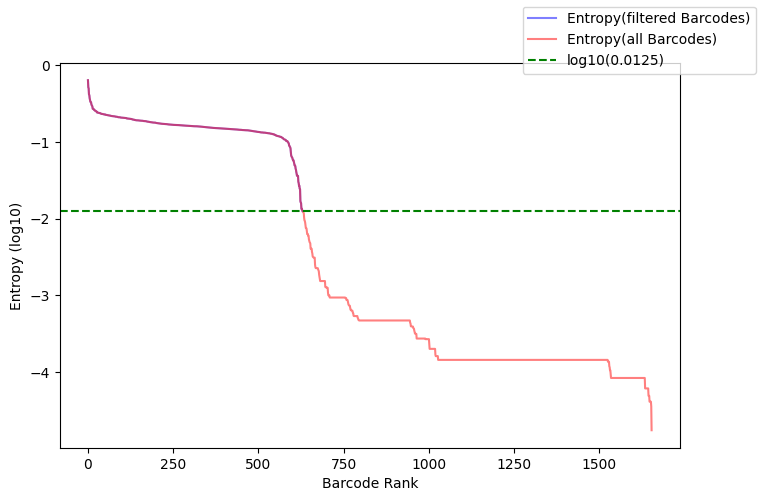

In [6]:
from IPython.display import Image
Image("sade_out/figures/chr1_entropy_knee_plot_logscale.png", width=600)


Above three inflection points were found by fitting entropy curve into spline and searching for inflection points (i.e., the second derivative flips sign and 1st derivative is local minimum). Take a look at SADE's written figure on entropy curve fit:

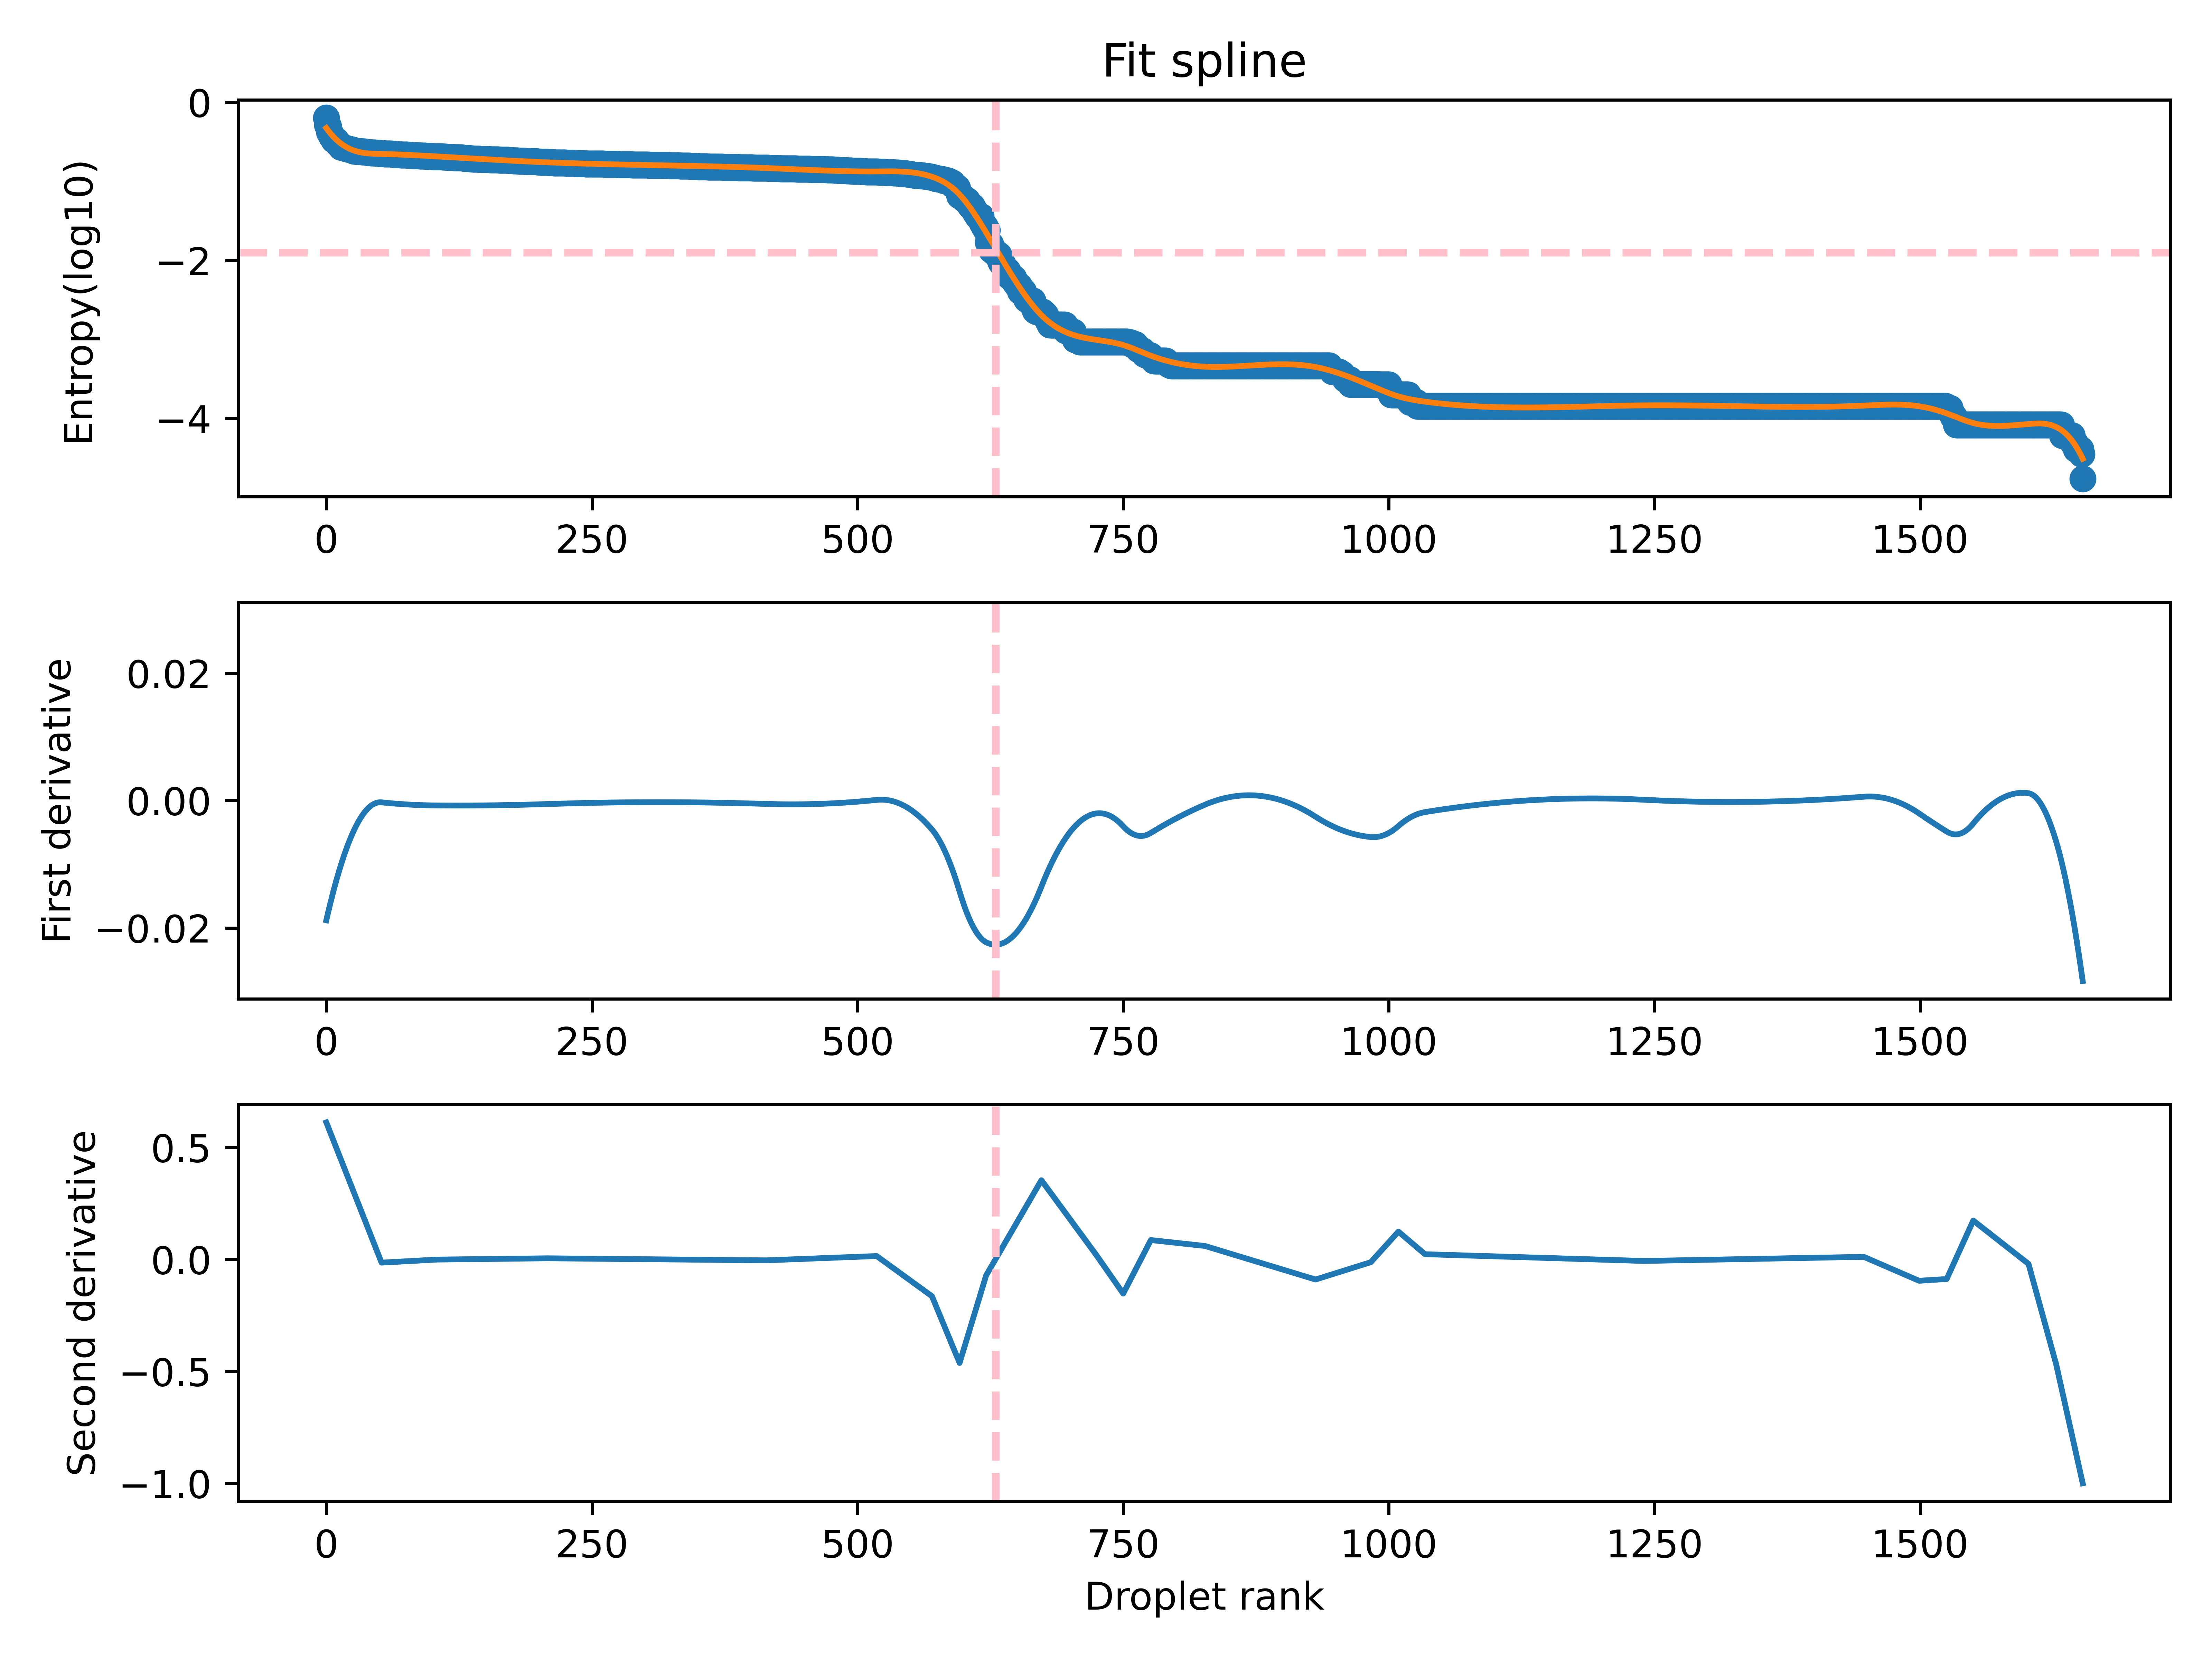

In [7]:

Image("sade_out/figures/chr1_entropy_threshold_fitting_k2_s1.png", width=600)

### Entropy histogram

The sharp drop is low-entropy population separates from high-entropy population, take a look at entropy distribution plot written by SADE `sade_out/figures/chr1_Entropy_histogram.png`: all scored barcodes in orange, the called barcodes in purple.


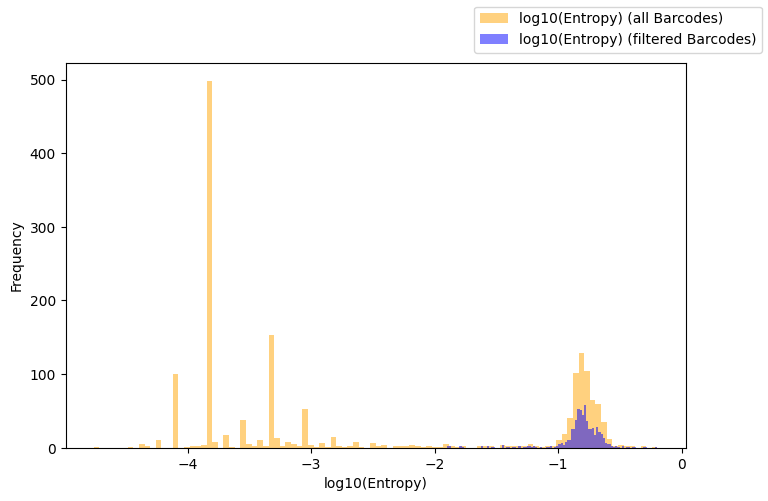

In [8]:
Image("sade_out/figures/chr1_Entropy_histogram.png", width=600)

- **Two populations.** The scored barcodes split into a low-entropy group (log10 entropy about −4.5 to −2.5) and a
  cell peak around −0.8.
- **The low group is empty droplets and debris.** Its tall, separated spikes (the highest, at about −3.8, holds about
  500 barcodes) come from barcodes with only a handful of chr1 insertions, whose entropy can take only a few discrete
  values. These are the flat steps at the bottom of the ranked curve.
- **The called barcodes (purple) are the cell peak.** The purple histogram uses finer bins, so its bars look lower
  than the orange ones over the same barcodes.
- **Between the two groups** there are few barcodes. The cutoff (log10 entropy −1.90) sits at the lower end of that
  gap, so the call set also takes in the thin spread between −1.9 and −1 (44 of the 630 called barcodes). These are
  the barcodes on the steep drop of the ranked curve before.

### Output files

| File | Contents |
|---|---|
| `calculated_barcode_entropy_df.tsv` | every scored barcode: `Entropy` plus the fitted model values (`Entropy_open_region`, `Mp` = non-empty chr1 windows, `mle_lambda`, `P0_open_region`, `P_open_state`) |
| `entropy_filtered_bc_w_Debrisflag_df.tsv` | the barcodes above the cutoff, with a `Debris` flag (`YES` = likely cellular debris: `P_open_state` > `-s`) |
| `bc_pass_entropy.tsv` | the called barcodes, one per line |
| `filtered_fragments.tsv` | the fragments of the called barcodes only, ready for downstream tools |
| `parameters.csv` | run settings and the entropy cutoff |
| `figures/` | the ranked-entropy knee plot, the curve fit and the entropy histogram |

The final cell calls are the barcodes with `Debris == NO`:


In [9]:
import pandas as pd
called = pd.read_csv("sade_out/entropy_filtered_bc_w_Debrisflag_df.tsv", index_col=0)
print(called.Debris.value_counts().to_dict())
called.head(2).round(2)

{'NO': 630}


,Entropy,Entropy_open_region,Mp,mle_lambda,P0_open_region,P_open_state,Debris
CCAATGAAGATATGTG-1,0.64,1.79,11792,0.88,0.41,0.24,NO
CTGTATTAGTGGTGTG-1,0.51,0.11,138,0.01,0.99,0.12,NO


## 4. Ranked entropy plot, coloured by cell call

SADE's cutoff comes from the ranked entropy curve: every scored barcode sorted from highest to lowest entropy. The
cells below redraw that curve from SADE's output tables (`calculated_barcode_entropy_df.tsv` and
`all_candidate_entropy_cutoffs.csv`), mark SADE's candidate inflection points and the chosen cutoff, and colour each
barcode by which caller called it a cell: SADE, Cell Ranger (`is__cell_barcode` in `singlecell.csv`), both or
neither.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# SADE: entropy of every scored barcode, the called (non-debris) cells, the cutoff and the candidate ranks
ent = pd.read_csv("sade_out/calculated_barcode_entropy_df.tsv", index_col=0)["Entropy"]
called = pd.read_csv("sade_out/entropy_filtered_bc_w_Debrisflag_df.tsv", index_col=0)
sade_cells = set(called.index[called.Debris == "NO"])
cutoff = float(open("sade_out/parameters.csv").read().split("entropy cutoff,")[1].split()[0])
cand_line = open("sade_out/all_candidate_entropy_cutoffs.csv").read()
candidates = [int(x) for x in cand_line.split(":")[1].split(",")]   # candidate inflection-point ranks

# Cell Ranger: is__cell_barcode = 1 for Cell Ranger cells
sc = pd.read_csv("data/atac_pbmc_500_nextgem_singlecell.csv", index_col=0)
cr_cells = set(sc.index[sc.is__cell_barcode == 1])

# rank the scored barcodes and label each with its call group
ranked = ent.sort_values(ascending=False).to_frame("entropy")
ranked["rank"] = np.arange(1, len(ranked) + 1)
is_s, is_c = ranked.index.isin(list(sade_cells)), ranked.index.isin(list(cr_cells))
ranked["group"] = np.select([is_s & is_c, is_s & ~is_c, ~is_s & is_c],
                            ["both", "SADE only", "Cell Ranger only"], "neither")
print(ranked.group.value_counts().to_dict())
print(f"SADE cells: {len(sade_cells)}, Cell Ranger cells: {len(cr_cells)}, shared: {len(sade_cells & cr_cells)}")

{'neither': 1024, 'both': 482, 'SADE only': 148}
SADE cells: 630, Cell Ranger cells: 484, shared: 482


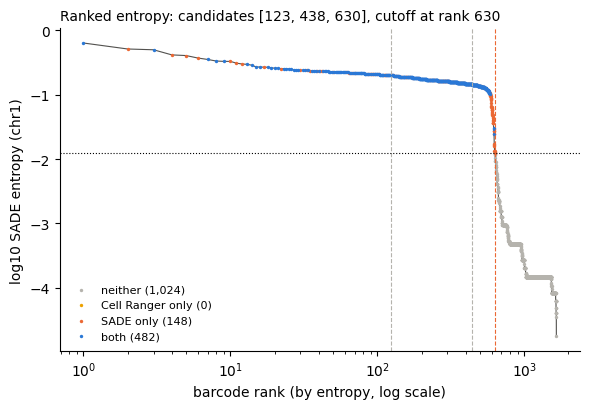

In [11]:
colors = {"neither": "#b5b3ad", "Cell Ranger only": "#eda100", "SADE only": "#eb6834", "both": "#2a78d6"}
rank_cutoff = len(sade_cells)                                       # SADE keeps the top-ranked barcodes

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(ranked["rank"], np.log10(ranked.entropy), color="#52514e", lw=0.8, zorder=1)
for g in ["neither", "Cell Ranger only", "SADE only", "both"]:
    m = ranked.group == g
    ax.scatter(ranked["rank"][m], np.log10(ranked.entropy[m]), s=6, c=colors[g], lw=0, zorder=2,
               label=f"{g} ({m.sum():,})")
for r in candidates:
    ax.axvline(r, color="#eb6834" if r == rank_cutoff else "#b5b3ad", ls="--", lw=0.8)
ax.axhline(np.log10(cutoff), color="black", ls=":", lw=0.8)
ax.set_xscale("log")
ax.set_xlabel("barcode rank (by entropy, log scale)")
ax.set_ylabel("log10 SADE entropy (chr1)")
ax.set_title(f"Ranked entropy: candidates {candidates}, cutoff at rank {rank_cutoff}", fontsize=10, loc="left")
ax.legend(fontsize=8, frameon=False, loc="lower left")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig("ranked_entropy_by_call.png", dpi=150)   # full-resolution copy in the working folder
plt.show()

### Reading the plot

- **Each point is one barcode** that SADE scored (1,654 here), placed by its entropy rank (x, log scale) and its chr1
  entropy (y).

- **SADE's entropy candidates (dashed lines) are ranks 123, 438 and 630.** The first two sit on the plateau; only the third
  sits on the drop, and SADE uses it as the cutoff (orange line; the dotted line is the matching entropy cutoff).
- **SADE now keeps almost every Cell Ranger cell:** 482 of 484 are called by both (blue). The other 2 are barcodes
  SADE could not score (too few chr1 insertions), so they do not appear in the plot.
- **SADE only (orange, 148):** majority sits on the plateau, mixed in with the cells both callers agree on. The
  rest sits past rank 560, on the steep drop just above the cutoff: the cutoff falls partway down the drop
  rather than at its top, so it lets in barcodes that are already falling towards the empty-droplet tail.
- **No Cell Ranger-only barcodes** remain in the plot.

Section 5 clusters the SADE-called cells and shows which clusters these low-entropy barcodes end up in.


## 5. Clustering the SADE-called cells with SnapATAC2

SADE's output is a cell set ready for downstream analysis. This section clusters the **630 SADE-called cells** with
SnapATAC2 (`pip install snapatac2`) and names the clusters from marker-gene accessibility. It takes about a minute;
the gene annotation for the marker step is downloaded on first use.

The steps:
1. **Count matrix:** import the fragments of the SADE-called barcodes and count them in 500 bp genome bins.
2. **Embedding and clustering:** select informative bins, spectral embedding, nearest-neighbour graph, Leiden
   clusters and UMAP.
3. **UMAP overlays:** colour the cells by cluster, by sequencing depth and by SADE entropy.

Note:
Instead of the whitelist used here, you can also start from **`sade_out/filtered_fragments.tsv`** (the fragments of the
called cells only; compress it with `gzip` first).

In [12]:
import warnings
warnings.filterwarnings("ignore")              # hide library warnings (tqdm, umap, numba, anndata)
import snapatac2 as snap

adata = snap.pp.import_fragments("data/atac_pbmc_500_nextgem_fragments.tsv.gz", chrom_sizes=snap.genome.hg38,
                                 whitelist=sorted(sade_cells), min_num_fragments=0, sorted_by_barcode=False,
                                 file="pbmc_sade.h5ad")   # SADE-called cells only (sade_cells from section 4)
snap.pp.add_tile_matrix(adata)                  # 500 bp bins
snap.pp.select_features(adata, verbose=False)
snap.tl.spectral(adata)
snap.pp.knn(adata)
snap.tl.leiden(adata, resolution=0.5)
snap.tl.umap(adata)
print(adata.n_obs, "cells,", adata.obs["leiden"].to_numpy().astype(int).max() + 1, "Leiden clusters")

630 cells, 5 Leiden clusters


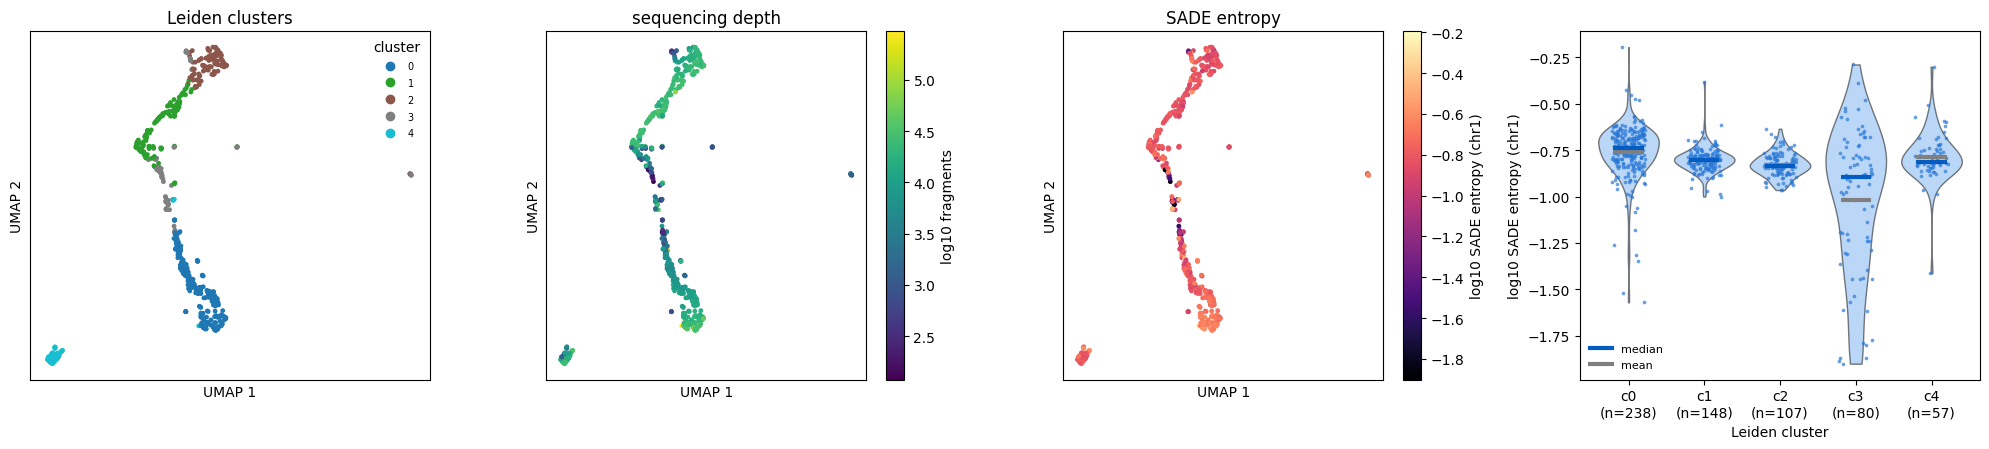

In [13]:
obs = adata.obs[:]
cluster = obs["leiden"].to_numpy().astype(int)
names = np.asarray(adata.obs_names)                            # barcodes, same order as cluster
depth = np.log10(obs["n_fragment"].to_numpy())
log_ent = np.log10(ent.reindex(names).to_numpy())              # SADE chr1 entropy (ent from section 4)
x, y = adata.obsm["X_umap"].T
order = np.random.default_rng(0).permutation(adata.n_obs)      # random draw order, so no cluster hides another

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
sc0 = axes[0].scatter(x[order], y[order], c=cluster[order], s=6, cmap="tab10")
axes[0].legend(*sc0.legend_elements(), title="cluster", frameon=False, fontsize=7, loc="best")
sc1 = axes[1].scatter(x[order], y[order], c=depth[order], s=6, cmap="viridis")
fig.colorbar(sc1, ax=axes[1], label="log10 fragments")
sc2 = axes[2].scatter(x[order], y[order], c=log_ent[order], s=6, cmap="magma")
fig.colorbar(sc2, ax=axes[2], label="log10 SADE entropy (chr1)")
for ax, title in zip(axes, ["Leiden clusters", "sequencing depth", "SADE entropy"]):
    ax.set(title=title, xticks=[], yticks=[], xlabel="UMAP 1", ylabel="UMAP 2")


clusters = np.unique(cluster)
data = [log_ent[cluster == c] for c in clusters]
vp = axes[3].violinplot(data, positions=range(len(clusters)), widths=0.8, showextrema=False, showmedians=True, showmeans=True )
for body in vp["bodies"]:
    body.set_facecolor("#78b0f1"); body.set_edgecolor("black"); body.set_alpha(0.5)
vp['cmedians'].set_linewidth(3); vp['cmedians'].set_color("#035cc2")
vp['cmeans'].set_linewidth(3); vp['cmeans'].set_color("grey")


rng = np.random.default_rng(0)
xpos = np.searchsorted(clusters, cluster) + rng.uniform(-0.22, 0.22, len(cluster))
axes[3].scatter(xpos, log_ent, s=7, c="#2a78d6", lw=0, alpha=0.7)
axes[3].set_xticks(range(len(clusters)), [f"c{c}\n(n={len(d)})" for c, d in zip(clusters, data)])
axes[3].set_xlabel("Leiden cluster")
axes[3].set_ylabel("log10 SADE entropy (chr1)")
axes[3].legend(handles=[plt.Line2D([0], [0], color="#035cc2", lw=3, label="median"),
                        plt.Line2D([0], [0], color="grey", lw=3, label="mean")],
               fontsize=8, frameon=False, loc="best")

fig.tight_layout()
fig.savefig("sade_cells_umap.png", dpi=150)
plt.show()


The 630 SADE-called cells form 5 Leiden clusters, cluster-3 has group level low read-depth and low entropy, likely are cells with insufficient read-depth to recover true signals.

Note: Leiden and UMAP results can differ slightly between SnapATAC2 versions and machines; this run used SnapATAC2 2.9.


### Marker gene accessibility at cluster level

To name the clusters, check chromatin accessibility at canonical PBMC marker genes:
1. **Gene matrix:** count each cell's fragments over every gene (gene body plus 2 kb upstream; SnapATAC2's gene
   activity score).
2. **Per-cluster signal:** normalise each cell to counts per 10,000, log-transform, and average per cluster.
3. **Heatmap:** z-score each gene across clusters. Red means more accessible than the average cluster, blue less.

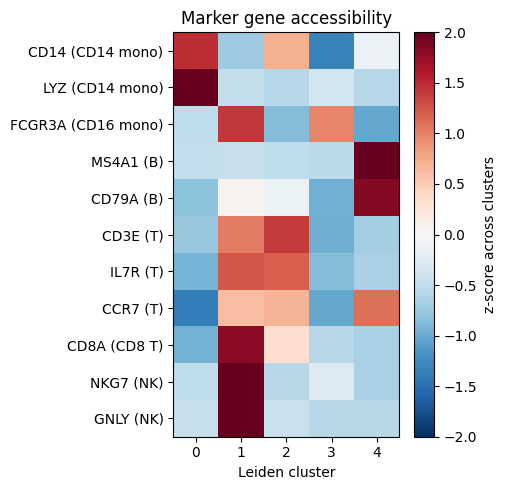

In [14]:
markers = {"CD14 mono": ["CD14", "LYZ"], "CD16 mono": ["FCGR3A"], "B": ["MS4A1", "CD79A"],
           "T": ["CD3E", "IL7R", "CCR7"], "CD8 T": ["CD8A"], "NK": ["NKG7", "GNLY"]}
genes = [g for gs in markers.values() for g in gs]
labels = [f"{g} ({ct})" for ct, gs in markers.items() for g in gs]

gmat = snap.pp.make_gene_matrix(adata, gene_anno=snap.genome.hg38)      # cells x genes
adata.close()
X = gmat.X.multiply(1e4 / gmat.X.sum(axis=1)).tocsr()[:, gmat.var_names.get_indexer(genes)]
X = np.log1p(X.toarray())
clusters = np.unique(cluster)
signal = np.array([X[cluster == c].mean(axis=0) for c in clusters]).T   # genes x clusters
z = (signal - signal.mean(axis=1, keepdims=True)) / signal.std(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(5, 5))
im = ax.imshow(z, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set(xticks=range(len(clusters)), xticklabels=clusters, yticks=range(len(genes)), yticklabels=labels,
       xlabel="Leiden cluster", title="Marker gene accessibility")
fig.colorbar(im, ax=ax, label="z-score across clusters")
fig.tight_layout()
fig.savefig("marker_heatmap.png", dpi=150)


The heatmap names the clusters:
- **Cluster 0: CD14 monocytes.** 
- **Cluster 1: cytotoxic lymphocytes (NK and CD8 T).** 
- **Cluster 2: T cells (mostly CD4).** R
- **Cluster 4: B cells.** 
- **Cluster 3: no clear cell type.** No marker stands out except a modest FCGR3A signal. Together with its very low
  depth and entropy, this looks like near-empty barcodes mixed with cells without efficient reads to recover signals.

So 550 of the 630 SADE-called cells fall into the four main PBMC groups: monocytes, cytotoxic lymphocytes, T cells and
B cells. The other 80 form the shallow, marker-less cluster 3. Marker accessibility is only a guide: for firmer
labels, transfer labels from a matched scRNA-seq reference.